# 02_05 Weibull

**Learning objectives**
- Model **lifetimes and failure times** with the Weibull, and read its **hazard rate** (the risk of failing right now, given survival so far).
- Understand the **shape** parameter: infant mortality ($k<1$), constant risk ($k=1$, the Exponential) and wear-out ($k>1$).
- Derive the survival function from the hazard, the mean (with the Gamma function), median and quantiles, and the weakest-link property.
- Solve three problems (hard-drive reliability, wind speed, a series system) by hand, in code and by simulation.

**Prerequisites:** [02_03 Exponential, Gamma and Erlang](02_03_exponential_gamma_erlang.ipynb) (the Exponential and its constant hazard), [02_02 Lognormal](02_02_lognormal.ipynb) (positive skewed data).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Survival function:** $S(t)=P(T>t)=1-F(t)$, the probability of lasting beyond time $t$.
- **Exponential($\lambda$):** constant failure rate; $S(t)=e^{-\lambda t}$; memoryless.
- **Gamma function:** $\Gamma(n)=(n-1)!$; $\Gamma(1)=1$, $\Gamma(\tfrac12)=\sqrt\pi$, $\Gamma(1.5)=0.8862$, $\Gamma(2)=1$.
- **Derivative and integral of exponentials:** $\frac d{dt}e^{-g(t)}=-g'(t)e^{-g(t)}$.
- **Logs:** $\ln(ab)=\ln a+\ln b$, used for the straight-line Weibull plot.

## 3. Intuition and story

### 3.1 Not every failure is a coin flip
The Exponential says a part is as likely to fail in the next hour whether it is brand new or 5 years old. Real components rarely behave this way:
- **Infant mortality:** defective units fail early, and the longer a unit survives the *safer* it becomes (risk decreases). Some electronics behave like this.
- **Random failures:** a constant risk (the Exponential).
- **Wear-out:** bearings, tires and hard drives degrade, so the risk of failing in the next hour *rises* with age.

The **hazard rate** $h(t)$ is the instantaneous risk of failing at time $t$ among units that are still working. The **Weibull** has a hazard that is a power of time, $h(t)\propto t^{k-1}$, so a single number $k$ covers all three behaviours.

### 3.2 The bathtub curve
Many real products have all three phases: early failures (falling hazard), a useful life (flat), then wear-out (rising). Adding a $k<1$, a $k=1$ and a $k>1$ hazard gives the famous **bathtub curve**, shown below.

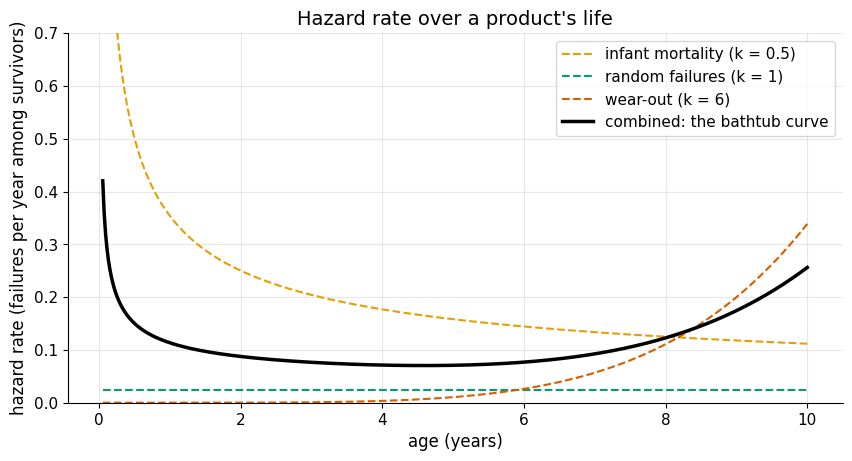

In [2]:
t_axis = np.linspace(0.05, 10, 500)
early = stats.weibull_min(0.5, scale=2).pdf(t_axis) / stats.weibull_min(0.5, scale=2).sf(t_axis)      # hazard = pdf / survival
flat = stats.expon(scale=40).pdf(t_axis) / stats.expon(scale=40).sf(t_axis)
wear = stats.weibull_min(6, scale=11).pdf(t_axis) / stats.weibull_min(6, scale=11).sf(t_axis)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(t_axis, early, "--", color=COLORS[1], label="infant mortality (k = 0.5)")
ax.plot(t_axis, flat, "--", color=COLORS[2], label="random failures (k = 1)")
ax.plot(t_axis, wear, "--", color=COLORS[3], label="wear-out (k = 6)")
ax.plot(t_axis, early * 0.25 + flat + wear * 0.6, color="black", linewidth=2.5, label="combined: the bathtub curve")
ax.set_ylim(0, 0.7)
ax.set_title("Hazard rate over a product's life")
ax.set_xlabel("age (years)")
ax.set_ylabel("hazard rate (failures per year among survivors)")
ax.legend()
plt.show()

**In plain words.** The hazard is "how risky is the next moment, given that I have survived so far". A falling hazard means survivors get safer, a flat one means no aging, a rising one means aging. The Weibull shape parameter $k$ tells you which.

## 4. Formal definition

**Weibull($k,\lambda$):** support $x\ge0$; shape $k>0$ and scale $\lambda>0$ (the **characteristic life**).
$$F(x)=1-e^{-(x/\lambda)^k},\qquad S(x)=e^{-(x/\lambda)^k},\qquad f(x)=\frac k\lambda\Big(\frac x\lambda\Big)^{k-1}e^{-(x/\lambda)^k}.$$
**Hazard rate and cumulative hazard:**
$$h(x)=\frac{f(x)}{S(x)}=\frac k\lambda\Big(\frac x\lambda\Big)^{k-1},\qquad H(x)=\int_0^xh=\Big(\frac x\lambda\Big)^k.$$
At $x=\lambda$: $F(\lambda)=1-e^{-1}=0.632$ for *every* shape: **63.2 % of units fail by the characteristic life**.

**`scipy` parametrization:** `stats.weibull_min(c=k, scale=lam)` (`c` is the shape). NumPy: `lam * rng.weibull(k, size)`.

## 5. Derivations

### 5.1 From hazard to survival
By definition $h(x)=\dfrac{f(x)}{S(x)}=-\dfrac{d}{dx}\ln S(x)$. Integrating from 0 and using $S(0)=1$: $S(x)=\exp\!\big(-\int_0^xh(u)du\big)=e^{-H(x)}$. With the power-law hazard $h(u)=\frac k\lambda(u/\lambda)^{k-1}$: $H(x)=(x/\lambda)^k$, giving the Weibull survival function. For $k=1$ the hazard is the constant $1/\lambda$: the Exponential.

**In plain words.** Survival is the exponential of minus the total hazard accumulated so far.

### 5.2 Density
$f(x)=h(x)S(x)=\frac k\lambda(x/\lambda)^{k-1}e^{-(x/\lambda)^k}$ (hazard times survival).

### 5.3 Mean (via the Gamma function)
$E[X]=\int_0^\infty S(x)dx=\int_0^\infty e^{-(x/\lambda)^k}dx$. Substitute $u=(x/\lambda)^k$, $x=\lambda u^{1/k}$, $dx=\frac\lambda ku^{1/k-1}du$:
$$E[X]=\frac\lambda k\int_0^\infty u^{1/k-1}e^{-u}du=\frac\lambda k\Gamma\!\Big(\frac1k\Big)=\lambda\,\Gamma\!\Big(1+\frac1k\Big).$$
More generally $E[X^n]=\lambda^n\Gamma(1+n/k)$, so
$$\mathrm{Var}(X)=\lambda^2\Big[\Gamma\!\Big(1+\frac2k\Big)-\Gamma\!\Big(1+\frac1k\Big)^2\Big].$$

### 5.4 Median and quantiles (the inverse CDF)
Set $F(x_p)=p$: $e^{-(x_p/\lambda)^k}=1-p\Rightarrow$
$$x_p=\lambda\big(-\ln(1-p)\big)^{1/k},\qquad\text{median}=\lambda(\ln2)^{1/k}.$$
This closed-form quantile function is also a **random number generator**: if $U\sim\text{Uniform}(0,1)$ then $\lambda(-\ln U)^{1/k}$ is Weibull (inverse transform sampling).

### 5.5 Mode
For $k>1$, setting $f'(x)=0$ gives $\text{mode}=\lambda\big(\tfrac{k-1}k\big)^{1/k}$; for $k\le1$ the mode is 0.

### 5.6 Power of an Exponential
If $X\sim\text{Weibull}(k,\lambda)$ then $(X/\lambda)^k\sim\text{Exponential}(1)$ (since $P((X/\lambda)^k>y)=P(X>\lambda y^{1/k})=e^{-y}$). A Weibull is an Exponential seen through a power transformation.

### 5.7 Weakest link: minimum of Weibulls
For $n$ independent identical Weibull($k,\lambda$) lifetimes, $P(\min>x)=S(x)^n=e^{-n(x/\lambda)^k}=e^{-(x/\lambda_n)^k}$ with $\lambda_n=\lambda n^{-1/k}$. **The minimum is Weibull with the same shape and a smaller scale.** A series system (fails when the first component fails) of $n$ Weibull parts is again Weibull.

### 5.8 Straight-line probability plot
Taking logs twice: $\ln\!\big(-\ln S(x)\big)=k\ln x-k\ln\lambda$. A plot of $\ln(-\ln(1-\hat F))$ against $\ln x$ is a straight line with slope $k$ and intercept $-k\ln\lambda$ if the data are Weibull. This **Weibull plot** is the standard tool in reliability engineering (section 11, Example 1).

### 5.9 Skewness (stated)
Skewness is positive for $k<3.6$, about 0 near $k=3.6$ (the Weibull looks Normal), and negative for larger $k$.

## 6. Properties and relationships

- **Exponential** is Weibull with $k=1$; **Rayleigh** (wind speed, noise magnitude) is Weibull with $k=2$.
- **Weakest link:** minima of Weibulls are Weibull (section 5.7); the **Gumbel** (02_07) is the limit for *maxima*.
- **Increasing / decreasing hazard:** $k>1$ is IFR (increasing failure rate), $k<1$ is DFR.
- **Not memoryless** unless $k=1$: $P(X>s+t\mid X>s)=e^{-[(s+t)^k-s^k]/\lambda^k}$ depends on $s$.
- **Close to Normal near $k\approx3.6$.**
- **Survival analysis:** the Weibull is a parametric baseline for the Cox / accelerated-failure-time models (Module 11).

## 7. 2D visuals

### 7.1 PDF, CDF and hazard of one Weibull
Weibull(k = 1.5, lambda = 5 years): the PDF peaks early, the CDF reaches 63 % at lambda, and the hazard rises steadily (wear-out).

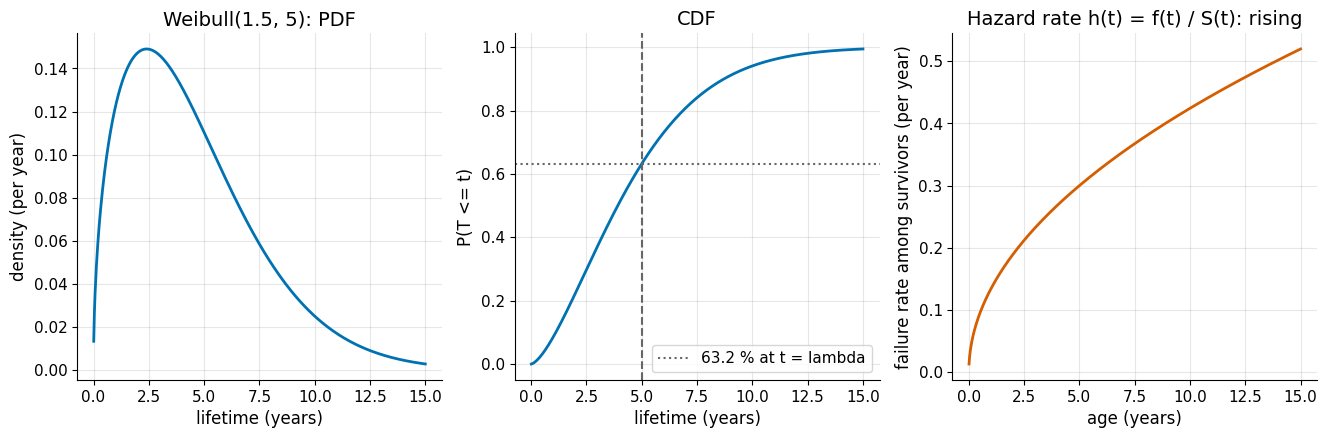

In [3]:
k, lam = 1.5, 5.0                                  # shape and scale (years)
dist = stats.weibull_min(c=k, scale=lam)
t_axis = np.linspace(0.01, 15, 500)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(t_axis, dist.pdf(t_axis), color=MAIN, linewidth=2)
axes[0].set_title("Weibull(1.5, 5): PDF")
axes[0].set_xlabel("lifetime (years)")
axes[0].set_ylabel("density (per year)")

axes[1].plot(t_axis, dist.cdf(t_axis), color=MAIN, linewidth=2)
axes[1].axhline(1 - np.exp(-1), color=NEUTRAL, linestyle=":", label="63.2 % at t = lambda")
axes[1].axvline(lam, color=NEUTRAL, linestyle="--")
axes[1].set_title("CDF")
axes[1].set_xlabel("lifetime (years)")
axes[1].set_ylabel("P(T <= t)")
axes[1].legend()

axes[2].plot(t_axis, dist.pdf(t_axis) / dist.sf(t_axis), color=HIGHLIGHT, linewidth=2)
axes[2].set_title("Hazard rate h(t) = f(t) / S(t): rising")
axes[2].set_xlabel("age (years)")
axes[2].set_ylabel("failure rate among survivors (per year)")
plt.show()

### 7.2 Effect of the shape k
Same scale, different shapes. k < 1: a spike at zero (early failures); k = 1: Exponential; k about 3.6: nearly symmetric bell; k large: failures bunched tightly around lambda.

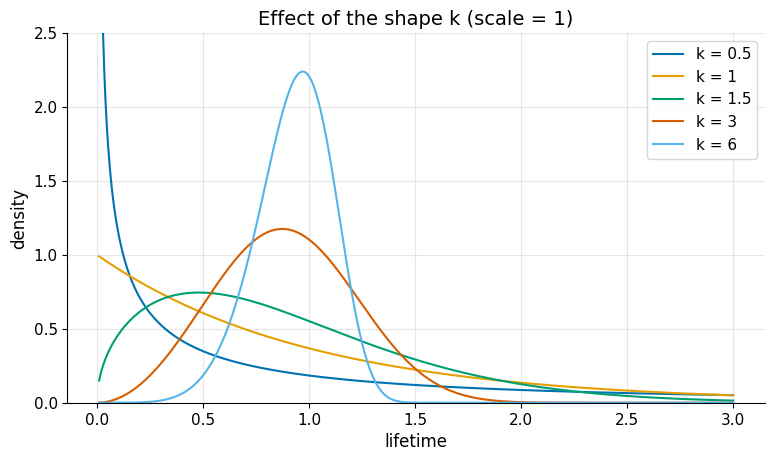

In [4]:
t_axis = np.linspace(0.01, 3, 500)
fig, ax = plt.subplots(figsize=(9, 4.8))
for shape, color in zip([0.5, 1, 1.5, 3, 6], COLORS + ["black"]):
    ax.plot(t_axis, stats.weibull_min(shape, scale=1).pdf(t_axis), color=color, label=f"k = {shape}")
ax.set_ylim(0, 2.5)
ax.set_title("Effect of the shape k (scale = 1)")
ax.set_xlabel("lifetime")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 7.3 The hazard tells the story
The hazard (not the density) shows aging most clearly: falling for k < 1, flat for k = 1, rising for k > 1.

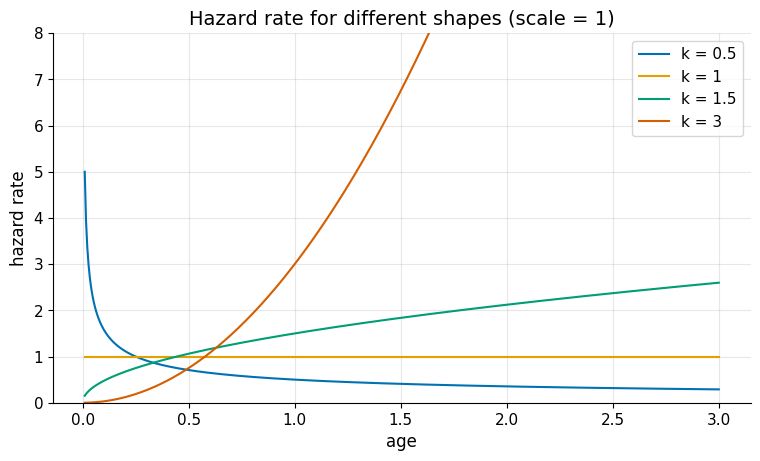

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for shape, color in zip([0.5, 1, 1.5, 3], COLORS):
    d = stats.weibull_min(shape, scale=1)
    ax.plot(t_axis, d.pdf(t_axis) / d.sf(t_axis), color=color, label=f"k = {shape}")
ax.set_ylim(0, 8)
ax.set_title("Hazard rate for different shapes (scale = 1)")
ax.set_xlabel("age")
ax.set_ylabel("hazard rate")
ax.legend()
plt.show()

### 7.4 Effect of the scale lambda and the survival curves
The scale stretches time: a larger lambda means longer lives. The right panel shows the survival curves, crossing 1/e = 0.37 at t = lambda.

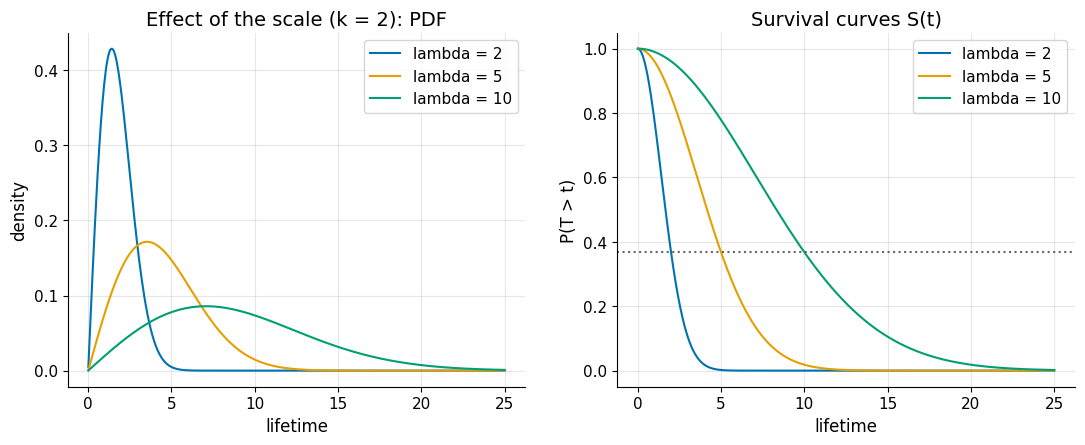

In [6]:
t_axis = np.linspace(0.01, 25, 500)
fig, (ax_pdf, ax_sf) = plt.subplots(1, 2, figsize=(13, 4.6))
for scale, color in zip([2, 5, 10], COLORS):
    d = stats.weibull_min(2, scale=scale)
    ax_pdf.plot(t_axis, d.pdf(t_axis), color=color, label=f"lambda = {scale}")
    ax_sf.plot(t_axis, d.sf(t_axis), color=color, label=f"lambda = {scale}")
ax_pdf.set_title("Effect of the scale (k = 2): PDF")
ax_pdf.set_xlabel("lifetime")
ax_pdf.set_ylabel("density")
ax_pdf.legend()
ax_sf.axhline(np.exp(-1), color=NEUTRAL, linestyle=":")
ax_sf.set_title("Survival curves S(t)")
ax_sf.set_xlabel("lifetime")
ax_sf.set_ylabel("P(T > t)")
ax_sf.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: PDF over (x, k), scale = 1
The surface morphs from an L-shape (k below 1) to a sharp bump around x = 1 (k large).

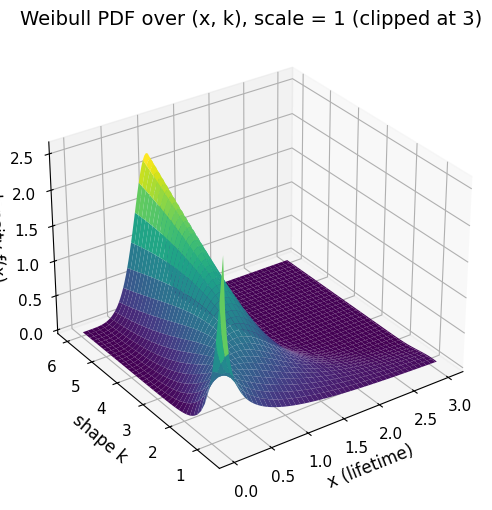

In [7]:
x_values = np.linspace(0.02, 3, 140)
k_values = np.linspace(0.6, 6, 40)
X, K = np.meshgrid(x_values, k_values)
Z = stats.weibull_min.pdf(X, K, scale=1)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, K, np.minimum(Z, 3), cmap="viridis", edgecolor="none")
ax.set_title("Weibull PDF over (x, k), scale = 1 (clipped at 3)")
ax.set_xlabel("x (lifetime)")
ax.set_ylabel("shape k")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-125)
plt.show()

### 8.2 Static: hazard over (x, k)
The hazard surface is easy to read: it is a power of x. Below k = 1 it falls with age, above it rises.

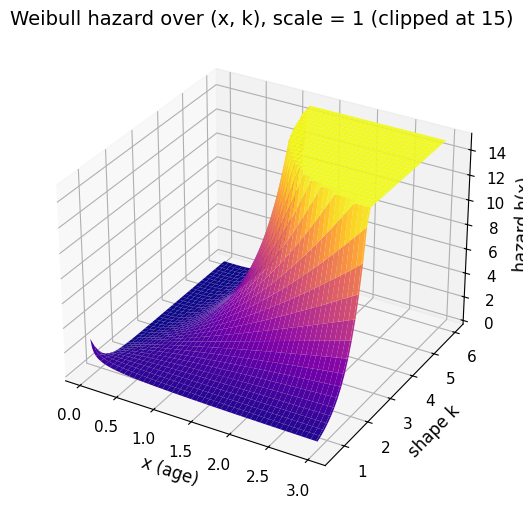

In [8]:
hazard = K * X ** (K - 1)                         # hazard with scale 1
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, K, np.minimum(hazard, 15), cmap="plasma", edgecolor="none")
ax.set_title("Weibull hazard over (x, k), scale = 1 (clipped at 15)")
ax.set_xlabel("x (age)")
ax.set_ylabel("shape k")
ax.set_zlabel("hazard h(x)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.3 Interactive Plotly version
The PDF surface of 8.1; drag to rotate.

In [9]:
fig = go.Figure(go.Surface(x=x_values, y=k_values, z=np.minimum(Z, 3), colorscale="Viridis"))
fig.update_layout(title="Weibull PDF over (x, k), scale = 1 (clipped at 3)", width=750, height=550,
                  scene=dict(xaxis_title="x (lifetime)", yaxis_title="shape k", zaxis_title="density f(x)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PDF
`numpy` draws a *standard* Weibull (scale 1); multiply by lambda.

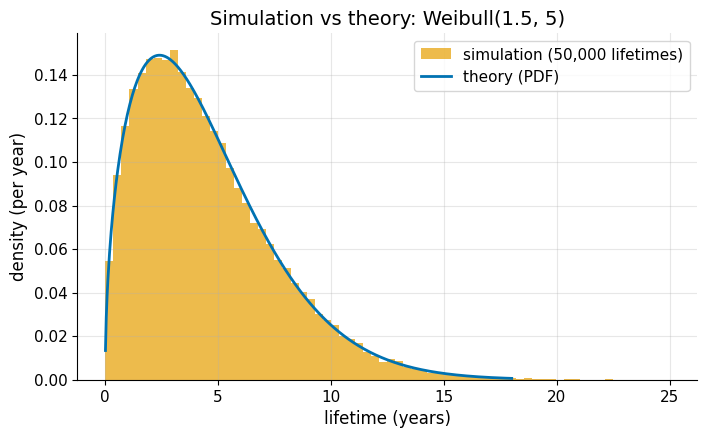

sample mean 4.514 vs theory lambda*Gamma(1+1/k) = 4.514


In [10]:
k, lam = 1.5, 5.0
samples = lam * rng.weibull(k, size=50_000)
t_axis = np.linspace(0.01, 18, 500)

fig, ax = plt.subplots()
ax.hist(samples, bins=70, density=True, color=SIM, alpha=0.7, label="simulation (50,000 lifetimes)")
ax.plot(t_axis, dist.pdf(t_axis), color=MAIN, linewidth=2, label="theory (PDF)")
ax.set_title("Simulation vs theory: Weibull(1.5, 5)")
ax.set_xlabel("lifetime (years)")
ax.set_ylabel("density (per year)")
ax.legend()
plt.show()
import math
print(f"sample mean {samples.mean():.3f} vs theory lambda*Gamma(1+1/k) = {lam * math.gamma(1 + 1 / k):.3f}")

### 9.2 Running mean converges to lambda * Gamma(1 + 1/k)

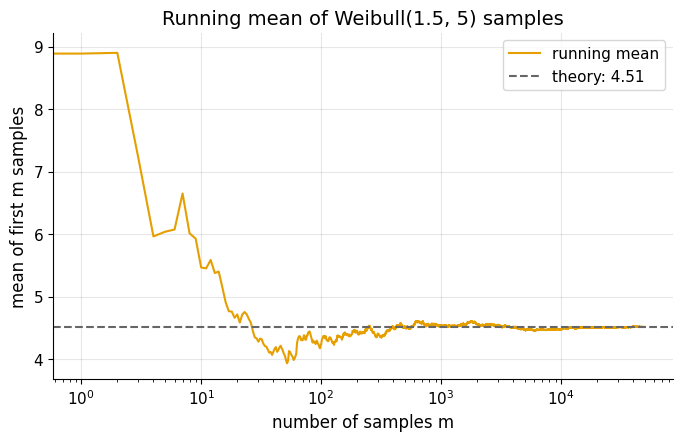

In [11]:
running_mean = np.cumsum(samples) / np.arange(1, len(samples) + 1)
fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(dist.mean(), color=NEUTRAL, linestyle="--", label=f"theory: {dist.mean():.2f}")
ax.set_xscale("log")
ax.set_title("Running mean of Weibull(1.5, 5) samples")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.legend()
plt.show()

### 9.3 Inverse-transform sampling and the Exponential link
We generate Weibull values from Uniform(0,1) with the quantile function lambda * (-ln U)^(1/k) of section 5.4, and check that (X / lambda)^k is Exponential(1).

KS test of the inverse-transform samples against Weibull(1.5, 5): p-value = 0.494
KS test of (X/lambda)^k against Exponential(1):                     p-value = 0.494


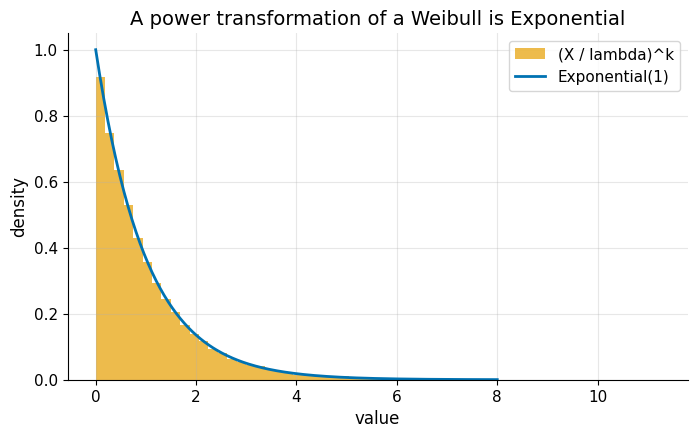

In [12]:
uniforms = rng.uniform(size=50_000)
by_inverse = lam * (-np.log(uniforms)) ** (1 / k)
powered = (by_inverse / lam) ** k

print("KS test of the inverse-transform samples against Weibull(1.5, 5): p-value =", round(stats.kstest(by_inverse, dist.cdf).pvalue, 3))
print("KS test of (X/lambda)^k against Exponential(1):                     p-value =", round(stats.kstest(powered, stats.expon.cdf).pvalue, 3))
fig, ax = plt.subplots()
ax.hist(powered, bins=60, density=True, color=SIM, alpha=0.7, label="(X / lambda)^k")
grid = np.linspace(0, 8, 300)
ax.plot(grid, stats.expon.pdf(grid), color=MAIN, linewidth=2, label="Exponential(1)")
ax.set_title("A power transformation of a Weibull is Exponential")
ax.set_xlabel("value")
ax.set_ylabel("density")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

Shape is called `c`.

In [13]:
d = stats.weibull_min(c=1.5, scale=5)
print("pdf(3)         :", round(d.pdf(3), 5))
print("cdf(3)         P(T <= 3):", round(d.cdf(3), 5))
print("sf(3)          P(T > 3) :", round(d.sf(3), 5))
print("ppf(0.02)      2nd percentile:", round(d.ppf(0.02), 4))
print("mean, std      :", round(d.mean(), 4), round(d.std(), 4))
print("median         :", round(d.median(), 4))
print("rvs(3)         :", d.rvs(size=3, random_state=1).round(3))
print("interval(0.9)  :", np.round(d.interval(0.9), 3))
print("stats mvsk     :", np.round(d.stats(moments="mvsk"), 3))

pdf(3)         : 0.146
cdf(3)         P(T <= 3): 0.37171
sf(3)          P(T > 3) : 0.62829
ppf(0.02)      2nd percentile: 0.3709
mean, std      : 4.5137 3.0647
median         : 3.9161
rvs(3)         : [3.314 5.876 0.012]
interval(0.9)  : [ 0.69  10.391]
stats mvsk     : [4.514 9.392 1.072 1.39 ]


**Fitting:** fix `floc=0` so only the shape and scale are estimated (maximum likelihood).

In [14]:
data = 5.0 * rng.weibull(1.5, size=500)
c_hat, loc_hat, scale_hat = stats.weibull_min.fit(data, floc=0)
print(f"true k = 1.5, lambda = 5 -> fitted k = {c_hat:.3f}, lambda = {scale_hat:.3f}")

true k = 1.5, lambda = 5 -> fitted k = 1.479, lambda = 5.310


## 11. Real-world worked examples

---
### Example 1 (main): hard-drive lifetimes

**Scenario (illustrative numbers).** A data center's hard drives have Weibull lifetimes with **shape $k=1.5$** (wear-out) and **scale $\lambda=5$ years**.

**Questions**
1. What is the probability that a drive **survives at least 3 years**?
2. What is the **mean time to failure (MTTF)**?
3. A manufacturer wants a **warranty period** such that only **2 %** of drives fail within it. How long is it?
4. A drive is **3 years old and working**. What is the probability that it survives **2 more years**? (Compare with a brand-new drive.)

### 11.1 By hand
**Q1.** $S(3)=e^{-(3/5)^{1.5}}$. $(0.6)^{1.5}=0.6\times\sqrt{0.6}=0.6\times0.7746=0.4648$, so $S(3)=e^{-0.4648}=0.6283$.

**Q2.** $E[T]=\lambda\Gamma(1+1/k)=5\,\Gamma(1.667)=5\times0.9027=4.513$ years.

**Q3.** $x_{0.02}=\lambda(-\ln0.98)^{1/k}=5\times(0.020203)^{0.6667}=5\times0.0742=0.371$ years (about 4.5 months).

**Q4.** The Weibull is not memoryless: $P(T>5\mid T>3)=\dfrac{S(5)}{S(3)}=\dfrac{e^{-1}}{e^{-0.4648}}=e^{-0.5352}=0.5855$, To judge aging, compare it with a *new* drive facing the same 2 years: $S(2)=e^{-(0.4)^{1.5}}=e^{-0.2530}=0.7765$. The 3-year-old drive has a worse chance (0.5855) than a new one (0.7765): wear-out.

In [15]:
import math

shape, scale = 1.5, 5.0

def survival_by_formula(x):
    # S(x) = exp(-(x / lambda)^k)
    return math.exp(-((x / scale) ** shape))

p_survive_3_hand = survival_by_formula(3)
mttf_hand = scale * math.gamma(1 + 1 / shape)
warranty_hand = scale * (-math.log(1 - 0.02)) ** (1 / shape)
p_old_drive_hand = survival_by_formula(5) / survival_by_formula(3)
p_new_drive_2_years_hand = survival_by_formula(2)
print(f"S(3) = {p_survive_3_hand:.4f}, MTTF = {mttf_hand:.3f} years, warranty = {warranty_hand:.3f} years")
print(f"3-year-old drive survives 2 more years: {p_old_drive_hand:.4f}; new drive survives 2 years: {p_new_drive_2_years_hand:.4f}")

S(3) = 0.6283, MTTF = 4.514 years, warranty = 0.371 years
3-year-old drive survives 2 more years: 0.5855; new drive survives 2 years: 0.7765


### 11.2 In code with `scipy`, and the asserts

In [16]:
drive = stats.weibull_min(c=shape, scale=scale)

assert np.isclose(p_survive_3_hand, drive.sf(3))
assert np.isclose(mttf_hand, drive.mean())
assert np.isclose(warranty_hand, drive.ppf(0.02))
assert np.isclose(p_old_drive_hand, drive.sf(5) / drive.sf(3))
assert np.isclose(p_new_drive_2_years_hand, drive.sf(2))
print(f"P(survive 3 years) = {drive.sf(3):.4f}; MTTF = {drive.mean():.3f}; median life = {drive.median():.3f}")
print(f"warranty period for 2 % failures = {drive.ppf(0.02):.3f} years = {drive.ppf(0.02) * 12:.1f} months")
print(f"hazard at 1 year = {drive.pdf(1) / drive.sf(1):.3f} per year; at 6 years = {drive.pdf(6) / drive.sf(6):.3f} per year")

P(survive 3 years) = 0.6283; MTTF = 4.514; median life = 3.916
warranty period for 2 % failures = 0.371 years = 4.5 months
hazard at 1 year = 0.134 per year; at 6 years = 0.329 per year


### 11.3 Verify by simulation
Simulate 500,000 drives; the age-conditioned probability is estimated among the drives that survive 3 years.

In [17]:
lifetimes = scale * rng.weibull(shape, size=500_000)
survivors_at_3 = lifetimes[lifetimes > 3]
print(f"P(survive 3 y): exact {drive.sf(3):.4f}  simulated {np.mean(lifetimes > 3):.4f}")
print(f"MTTF:           exact {drive.mean():.3f}  simulated {lifetimes.mean():.3f}")
print(f"2nd percentile: exact {drive.ppf(0.02):.3f}  simulated {np.percentile(lifetimes, 2):.3f}")
print(f"3-year-old drive survives 2 more years: exact {p_old_drive_hand:.4f}  simulated {np.mean(survivors_at_3 > 5):.4f}")
assert abs(np.mean(lifetimes > 3) - drive.sf(3)) < 0.003
assert abs(np.mean(survivors_at_3 > 5) - p_old_drive_hand) < 0.004

P(survive 3 y): exact 0.6283  simulated 0.6274
MTTF:           exact 4.514  simulated 4.508
2nd percentile: exact 0.371  simulated 0.371
3-year-old drive survives 2 more years: exact 0.5855  simulated 0.5844


### 11.4 Plots with the regions shaded

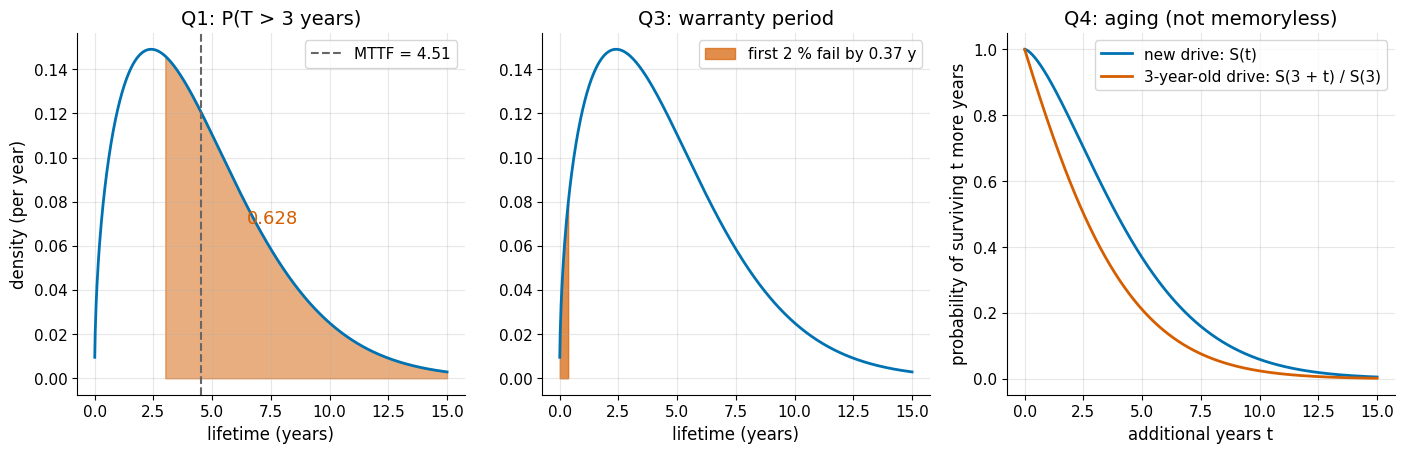

In [18]:
t_axis = np.linspace(0.005, 15, 800)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

alive = t_axis >= 3
axes[0].plot(t_axis, drive.pdf(t_axis), color=MAIN, linewidth=2)
axes[0].fill_between(t_axis[alive], drive.pdf(t_axis[alive]), color=HIGHLIGHT, alpha=0.5)
axes[0].axvline(drive.mean(), color=NEUTRAL, linestyle="--", label=f"MTTF = {drive.mean():.2f}")
axes[0].set_title("Q1: P(T > 3 years)")
axes[0].text(6.5, 0.07, f"{drive.sf(3):.3f}", color=HIGHLIGHT, fontsize=13)
axes[0].set_xlabel("lifetime (years)")
axes[0].set_ylabel("density (per year)")
axes[0].legend()

early = t_axis <= drive.ppf(0.02)
axes[1].plot(t_axis, drive.pdf(t_axis), color=MAIN, linewidth=2)
axes[1].fill_between(t_axis[early], drive.pdf(t_axis[early]), color=HIGHLIGHT, alpha=0.7, label=f"first 2 % fail by {drive.ppf(0.02):.2f} y")
axes[1].set_title("Q3: warranty period")
axes[1].set_xlabel("lifetime (years)")
axes[1].legend()

axes[2].plot(t_axis, drive.sf(t_axis), color=MAIN, linewidth=2, label="new drive: S(t)")
conditional = drive.sf(3 + t_axis) / drive.sf(3)
axes[2].plot(t_axis, conditional, color=HIGHLIGHT, linewidth=2, label="3-year-old drive: S(3 + t) / S(3)")
axes[2].set_title("Q4: aging (not memoryless)")
axes[2].set_xlabel("additional years t")
axes[2].set_ylabel("probability of surviving t more years")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- **63 % of drives survive 3 years**, and the average life (MTTF) is **4.5 years**, shorter than the characteristic life of 5 years.
- A **3-year-old drive has only a 59 % chance of lasting 2 more years**, while a new drive has 78 %: the drives wear out, so risk increases with age. With the Exponential (memoryless) model the two would be equal.
- A warranty of about **4.5 months** keeps early failures to 2 %.
- **Decision:** replace drives proactively before about year 4 (hazard keeps rising) and keep spares for the failures. Use the warranty only for the early failures; it says little about the lifetime that matters for the replacement plan.

### Weibull plot: estimating the shape from data
We simulate 200 drive lifetimes, fit by maximum likelihood, and also use the straight-line **Weibull plot** of section 5.8. The slope of the line is the shape $k$.

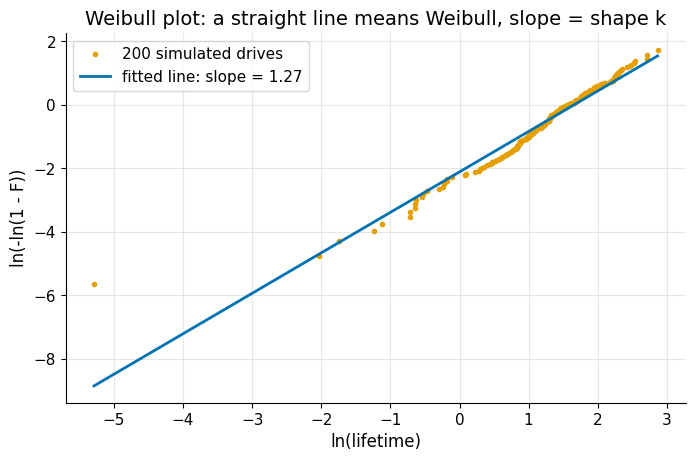

maximum likelihood: k = 1.45, lambda = 5.00; plot slope: k = 1.27; scale from the plot: 5.23 (truth 1.5 and 5)


In [19]:
observed = scale * rng.weibull(shape, size=200)
c_hat, _, scale_hat = stats.weibull_min.fit(observed, floc=0)

sorted_data = np.sort(observed)
ranks = np.arange(1, len(sorted_data) + 1)
empirical_cdf = (ranks - 0.3) / (len(sorted_data) + 0.4)           # median-rank estimate
x_plot = np.log(sorted_data)
y_plot = np.log(-np.log(1 - empirical_cdf))
slope, intercept = np.polyfit(x_plot, y_plot, deg=1)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(x_plot, y_plot, ".", color=SIM, label="200 simulated drives")
ax.plot(x_plot, slope * x_plot + intercept, color=MAIN, linewidth=2, label=f"fitted line: slope = {slope:.2f}")
ax.set_title("Weibull plot: a straight line means Weibull, slope = shape k")
ax.set_xlabel("ln(lifetime)")
ax.set_ylabel("ln(-ln(1 - F))")
ax.legend()
plt.show()
print(f"maximum likelihood: k = {c_hat:.2f}, lambda = {scale_hat:.2f}; plot slope: k = {slope:.2f}; scale from the plot: {np.exp(-intercept / slope):.2f} (truth 1.5 and 5)")

---
### Example 2: wind speed and wind power (Rayleigh, k = 2)

**Scenario (illustrative).** At a wind-turbine site, hourly wind speed (m/s) is Weibull with $k=2$ and $\lambda=8$ m/s.

**Questions:** (a) the mean wind speed; (b) the probability the wind exceeds 15 m/s (shutdown speed); (c) the average of $v^3$ (wind power is proportional to the cube of speed).

**By hand.** (a) $8\,\Gamma(1.5)=8\times0.8862=7.09$ m/s. (b) $S(15)=e^{-(15/8)^2}=e^{-3.516}=0.0297$. (c) $E[v^3]=\lambda^3\Gamma(1+3/2)=512\times\Gamma(2.5)=512\times1.3293=680.6$, much more than the cube of the mean speed ($7.09^3=356$). Because power grows as the cube, **the windy hours produce most of the energy** (the simulation below shows that the windiest quarter of the hours delivers about 73 %).

In [20]:
wind = stats.weibull_min(c=2, scale=8)
mean_wind_hand = 8 * math.gamma(1.5)
p_over_15_hand = math.exp(-((15 / 8) ** 2))
third_moment_hand = 8**3 * math.gamma(1 + 3 / 2)
assert np.isclose(mean_wind_hand, wind.mean())
assert np.isclose(p_over_15_hand, wind.sf(15))
assert np.isclose(third_moment_hand, wind.moment(3))
print(f"mean wind {wind.mean():.2f} m/s; P(> 15 m/s) = {wind.sf(15):.4f}; E[v^3] = {wind.moment(3):.1f} vs (mean)^3 = {wind.mean() ** 3:.1f}")

speeds = 8 * rng.weibull(2, size=500_000)
print(f"simulation: mean {speeds.mean():.2f}, P(>15) = {np.mean(speeds > 15):.4f}, E[v^3] = {np.mean(speeds ** 3):.1f}")
top_hours = speeds > np.percentile(speeds, 75)
print(f"the windiest 25 % of hours deliver {np.sum(speeds[top_hours] ** 3) / np.sum(speeds ** 3):.0%} of the total cubic power")
assert abs(np.mean(speeds > 15) - wind.sf(15)) < 0.002

mean wind 7.09 m/s; P(> 15 m/s) = 0.0297; E[v^3] = 680.6 vs (mean)^3 = 356.4
simulation: mean 7.09, P(>15) = 0.0297, E[v^3] = 681.0
the windiest 25 % of hours deliver 73% of the total cubic power


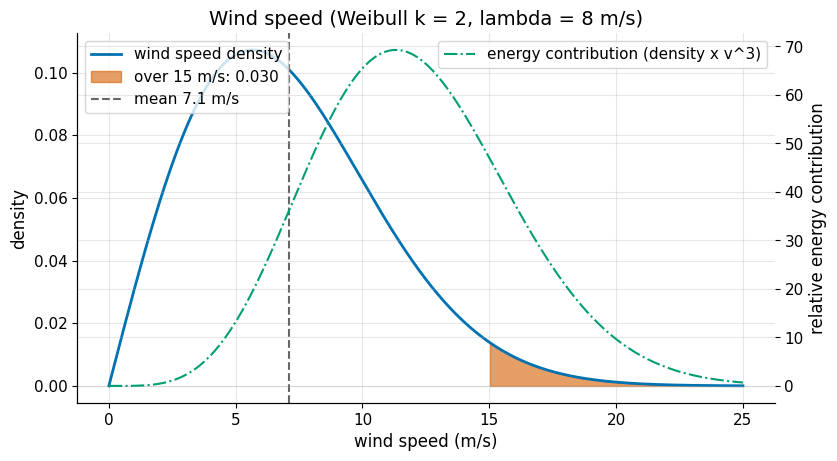

In [21]:
v_axis = np.linspace(0, 25, 500)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(v_axis, wind.pdf(v_axis), color=MAIN, linewidth=2, label="wind speed density")
over = v_axis > 15
ax.fill_between(v_axis[over], wind.pdf(v_axis[over]), color=HIGHLIGHT, alpha=0.6, label=f"over 15 m/s: {wind.sf(15):.3f}")
ax.axvline(wind.mean(), color=NEUTRAL, linestyle="--", label=f"mean {wind.mean():.1f} m/s")
ax2 = ax.twinx()
ax2.plot(v_axis, wind.pdf(v_axis) * v_axis**3, color=COLORS[2], linestyle="-.", label="energy contribution (density x v^3)")
ax2.set_ylabel("relative energy contribution")
ax.set_title("Wind speed (Weibull k = 2, lambda = 8 m/s)")
ax.set_xlabel("wind speed (m/s)")
ax.set_ylabel("density")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.show()

**Interpretation.** The mean wind of 7.1 m/s does not describe the energy: the cube emphasizes the tail, so the **average of v cubed is almost twice the cube of the average speed**. Sites are therefore evaluated with the full Weibull, not just the mean. A shutdown threshold at 15 m/s is hit about 3 % of the time.

---
### Example 3: a series system and the weakest link

**Scenario (illustrative).** A machine has **4 identical parts in series** (it stops when the first part fails). Each part has Weibull lifetime with $k=2.5$ and $\lambda=1000$ hours.

**Questions:** (a) the distribution of the machine's lifetime; (b) the probability that the machine survives 500 hours; (c) how many parts could a machine have so that it survives 500 hours with at least 90 % probability?

**By hand.** (a) By the weakest-link property (5.7) the machine is Weibull($k=2.5$, $\lambda_4=1000	imes4^{-1/2.5}=574.3$ h). (b) $S(500)=e^{-(500/574.3)^{2.5}}=e^{-0.7071}=0.4930$... check by multiplying: each part survives 500 h with probability $e^{-(0.5)^{2.5}}=e^{-0.1768}=0.8379$, and $0.8379^4=0.4930$. (c) Need $0.8379^n\ge0.9\Rightarrow n\le\ln0.9/\ln0.8379=0.59$: not even one part reaches 90 %.

In [22]:
part = stats.weibull_min(c=2.5, scale=1000)
n_parts = 4
machine_scale_hand = 1000 * n_parts ** (-1 / 2.5)
machine = stats.weibull_min(c=2.5, scale=machine_scale_hand)

p_machine_500_hand = part.sf(500) ** n_parts             # all 4 parts must survive
assert np.isclose(p_machine_500_hand, machine.sf(500))
print(f"machine scale = {machine_scale_hand:.1f} h; P(machine survives 500 h) = {machine.sf(500):.4f} (= {part.sf(500):.4f}^4)")
print(f"one part survives 500 h with probability {part.sf(500):.4f}; machine MTTF = {machine.mean():.0f} h vs a single part {part.mean():.0f} h")

simulated_parts = 1000 * rng.weibull(2.5, size=(300_000, n_parts))
machine_life = simulated_parts.min(axis=1)                 # the first failure stops the machine
print(f"simulation: P(survive 500 h) = {np.mean(machine_life > 500):.4f}; mean life {machine_life.mean():.0f} h")
assert abs(np.mean(machine_life > 500) - machine.sf(500)) < 0.004

machine scale = 574.3 h; P(machine survives 500 h) = 0.4931 (= 0.8380^4)
one part survives 500 h with probability 0.8380; machine MTTF = 510 h vs a single part 887 h
simulation: P(survive 500 h) = 0.4936; mean life 510 h


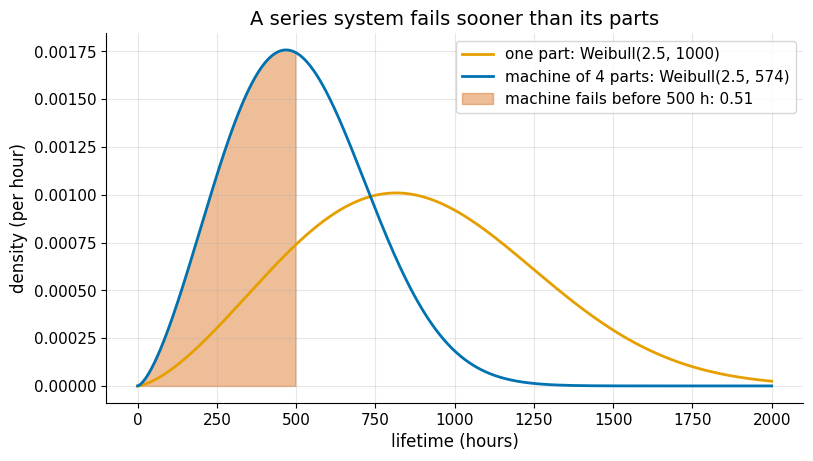

In [23]:
t_axis = np.linspace(0, 2000, 600)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(t_axis, part.pdf(t_axis), color=COLORS[1], linewidth=2, label="one part: Weibull(2.5, 1000)")
ax.plot(t_axis, machine.pdf(t_axis), color=MAIN, linewidth=2, label=f"machine of 4 parts: Weibull(2.5, {machine_scale_hand:.0f})")
before = t_axis <= 500
ax.fill_between(t_axis[before], machine.pdf(t_axis[before]), color=HIGHLIGHT, alpha=0.4, label=f"machine fails before 500 h: {machine.cdf(500):.2f}")
ax.set_title("A series system fails sooner than its parts")
ax.set_xlabel("lifetime (hours)")
ax.set_ylabel("density (per hour)")
ax.legend()
plt.show()

**Interpretation.** Chaining 4 parts divides the characteristic life by $4^{1/2.5}=1.74$ (from 1000 to 574 hours). The machine survives 500 hours only about **49 % of the time**, although each part individually survives 84 % of the time. **Decision:** for reliability, reduce the number of single points of failure or add redundancy (parallel components), because the weakest link governs a series system.

## 12. Where it is used

### Statistics
- **Survival and reliability analysis:** Weibull regression and accelerated-failure-time models; the Weibull plot for diagnosing failure mechanisms.
- **Extreme values:** the Weibull is one of the three extreme-value types (for minima of bounded variables).
- **Censored data:** maximum likelihood handles units that have not failed yet (Module 11).

### Data science
- **Churn and customer lifetime:** time until a customer leaves, with risk that grows or shrinks with tenure (Module 11).
- **Predictive maintenance:** remaining useful life of equipment, spare-parts planning, warranty cost.
- **Wind and renewable energy** resource assessment (Example 2).

### ML and AI
- **Survival models:** Weibull time-to-event heads in deep survival networks (e.g. WTTE-RNN).
- **Failure prediction** and cohort retention curves.
- **Link to Gumbel/extremes** in robustness and tail-risk modelling.

## 13. Common pitfalls and misconceptions

- **Shape vs scale confusion:** the shape k controls the *behaviour* (hazard rising or falling); the scale is just the time unit. Do not read the scale as the mean (the mean is lambda times Gamma(1 + 1/k)).
- **Convention:** `numpy` `rng.weibull(k)` gives a standard Weibull (scale 1); multiply by lambda. `scipy.weibull_min(c, scale)` is the same family. `weibull_max` is the mirror-image, not what you want for lifetimes.
- **Not memoryless:** quoting "the chance it survives another year" must depend on its age (unless k = 1).
- **Fit with `floc=0`:** otherwise `scipy` also estimates a location shift and the fit may be unstable.
- **Censoring:** units still working at the end of a study are *not* failures; dropping them biases the lifetimes downward (Module 11).
- **A straight Weibull plot with k near 1 suggests random failures:** replacement by age is then pointless.

## 14. Exercises

1. A component has Weibull($k=2$, $\lambda=100$ hours). Find $P(T>80)$ and the median life.
2. For which values of $k$ is the hazard decreasing, constant and increasing? Give an example of a product for each.
3. A battery has Weibull($k=3$, $\lambda=200$ h). Find the mean life and the time by which 10 % have failed.
4. Show that the Weibull with $k=1$ is the Exponential and that its hazard is constant.
5. Using code, find the shape $k$ for which the Weibull skewness is approximately zero.
6. A system has 3 identical independent Weibull($k=1.5$, $\lambda=2$ years) parts in series. What is the distribution of its lifetime and the probability it lasts more than 1 year?
7. (Harder) Derive $E[T]=\lambda\Gamma(1+1/k)$ using the substitution $u=(x/\lambda)^k$.
8. (Harder) Show that $\min(T_1,\dots,T_n)$ for iid Weibull($k,\lambda$) is Weibull($k,\lambda n^{-1/k}$), and for $k=2$, $\lambda=100$, $n=10$ compute the probability that the minimum exceeds 40.

Solutions are at the end.

## 15. Summary table

| Item | Value |
|---|---|
| Parameters | shape k > 0, scale lambda > 0 |
| Support | x >= 0 |
| CDF / survival | 1 - exp(-(x/lambda)^k) / exp(-(x/lambda)^k) |
| Hazard | (k/lambda) (x/lambda)^(k-1) |
| Mean | lambda Gamma(1 + 1/k) |
| Variance | lambda^2 [Gamma(1 + 2/k) - Gamma(1 + 1/k)^2] |
| Median | lambda (ln 2)^(1/k) |
| Quantile | lambda (-ln(1 - p))^(1/k) |
| When to use | lifetimes and times to failure with rising (k > 1) or falling (k < 1) risk; wind speed (k = 2) |
| `scipy` name | `stats.weibull_min(c=k, scale=lambda)` |

## Solutions

In [24]:
c1 = stats.weibull_min(2, scale=100)
print("1: P(T>80) =", round(c1.sf(80), 4), " median =", round(c1.median(), 2), "(= 100 * sqrt(ln 2) =", round(100 * np.sqrt(np.log(2)), 2), ")")
b3 = stats.weibull_min(3, scale=200)
print("3: mean", round(b3.mean(), 2), " 10th percentile", round(b3.ppf(0.10), 2))
from scipy import optimize
k_zero = optimize.brentq(lambda c: stats.weibull_min(c).stats(moments="s"), 2.0, 6.0)
print("5: skewness is zero for k =", round(float(k_zero), 3))
system = stats.weibull_min(1.5, scale=2 * 3 ** (-1 / 1.5))
print("6: system scale", round(2 * 3 ** (-1 / 1.5), 4), " P(lasts > 1 year) =", round(system.sf(1), 4), "=", round(stats.weibull_min(1.5, scale=2).sf(1) ** 3, 4))
m8 = stats.weibull_min(2, scale=100 * 10 ** (-1 / 2))
print("8: scale of the minimum", round(100 * 10 ** (-1 / 2), 3), " P(min > 40) =", round(m8.sf(40), 4), "=", round(stats.weibull_min(2, scale=100).sf(40) ** 10, 4))

1: P(T>80) = 0.5273  median = 83.26 (= 100 * sqrt(ln 2) = 83.26 )
3: mean 178.6  10th percentile 94.46
5: skewness is zero for k = 3.602
6: system scale 0.9615  P(lasts > 1 year) = 0.3462 = 0.3462
8: scale of the minimum 31.623  P(min > 40) = 0.2019 = 0.2019


**1.** $S(80)=e^{-(0.8)^2}=e^{-0.64}=0.5273$; median $=100\sqrt{\ln2}=83.2$ hours.

**2.** $k<1$: decreasing (infant mortality, e.g. early electronics failures); $k=1$: constant (random shocks, e.g. a power surge); $k>1$: increasing (wear-out, e.g. bearings, tires).

**3.** Mean $=200\,\Gamma(1+1/3)=200\times0.8930=178.6$ h; $x_{0.10}=200(-\ln0.9)^{1/3}=200\times0.472=94.5$ h.

**4.** For $k=1$, $S(x)=e^{-x/\lambda}$ (Exponential with mean $\lambda$) and $h(x)=\frac1\lambda(x/\lambda)^0=\frac1\lambda$: constant.

**5.** The skewness is zero near $k\approx3.60$.

**6.** The series system is Weibull($1.5,\,2\times3^{-1/1.5}=0.96$ years); $P(>1)pprox0.346$ (printed), equal to $S_{\text{part}}(1)^3$.

**7.** See section 5.3: with $u=(x/\lambda)^k$ the integral of $e^{-(x/\lambda)^k}$ becomes $\frac\lambda k\Gamma(1/k)=\lambda\Gamma(1+1/k)$.

**8.** $S_{\min}(x)=S(x)^n=e^{-n(x/\lambda)^k}=e^{-(x/(\lambda n^{-1/k}))^k}$. For $k=2,\lambda=100,n=10$: scale $31.62$, $P(>40)=e^{-(40/31.62)^2}=e^{-1.6}=0.2019$.